In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

df = pd.read_csv('../data/final_metropole/Merge_final_2.csv', dtype={"code_dept": str})
df["date"] = pd.to_datetime(df["date_semaine"] + "-1", format="%G-S%V-%u")

CIBLE = "TousAge_allergie_urgences"
EXOS = ['As in PM10', 'BaP in PM10', 'Cd in PM10','Ni in PM10', 'Pb in PM10', 'NO2', 'O3', 'PM10', 'PM2.5', 'SO2',
        'Chl in PM1', 'NO3 in PM1', 'NH4 in PM1', 'Org in PM1', 'SO4 in PM1','pression_mer', 'tendance_pression_3h', 
        'vent_vitesse', 'temperature_kelvin', 'humidite_relative', 'visibilite','pression_station', 'precipitation_3h', 
        'tp_averses_ou_orages','tp_brouillard', 'tp_brume_fumee_ou_phenomenes_particuliers','tp_neige_precipitation_solide',
        'tp_phenomenes_recents_derniere_heure', 'tp_pluie_ou_bruine', 'tp_sans_precipitation_visibilite_ou_nuages',
        'tp_tempete_poussiere_chasse_neige', 'TousAge_asthme_urgences', 'TousAge_asthme_hospitalisation', 
        '0an_bronchiolite_urgences', 'TousAge_allergie_hospitalisation','prev_calc_Maladie_Respi_Chronique_0-14_9',
        'prev_calc_Maladie_Respi_Chronique_15-64_9', 'prev_calc_Maladie_Respi_Chronique_65+_9', 'pct_urbain', 'pct_artisans', 
        'pct_cadres', 'pct_prof_inter', 'pct_employes', 'pct_ouvriers', 'pct_retraites', 'pct_agriculteurs', 
        'densite_generalistes', 'densite_pediatres','densite_pneumologues', 'densite_allergologues', 'densite_kines','sos_present']

H = 2 # nombre de semaines futures moyennées

# Une ligne par département et par semaine t : cible = moyenne de y(t+1)..y(t+H)
morceaux = []
for dept, d in df.groupby("code_dept"):
    d = d.drop_duplicates("date").set_index("date").sort_index().asfreq("W-MON")
    y = d[CIBLE]
    sem = d.index.isocalendar().week.astype(float)
    moy_glis = y.rolling(H, min_periods=H).mean()
    bloc = pd.DataFrame({
        "code_dept": dept,
        "date_debut": d.index + pd.Timedelta(weeks=1),
        "date_fin": d.index + pd.Timedelta(weeks=H),
        "cible": moy_glis.shift(-H),         
        "y_lag0": y,
        #"y_passe": moy_glis, "y_lag1": y.shift(1), "y_lag2": y.shift(2),
        "y_moy2": (y + y.shift(1)) / 2,
        "sem_sin": np.sin(2 * np.pi * sem / 52),
        "sem_cos": np.cos(2 * np.pi * sem / 52),
    })
    bloc[EXOS] = d[EXOS]
    morceaux.append(bloc)
    
#panel = pd.concat(morceaux).dropna(subset=["cible", "y_passe", "y_lag0", "y_lag1", "y_lag2"])
panel = pd.concat(morceaux).dropna(subset=["cible", "y_moy2"])

# Split 2021/2022 = TRAIN, 2023 = VAL, 2024 = TEST
an = panel["date_fin"].dt.year
panel["split"] = "test"
panel.loc[an <= 2022, "split"] = "train"
panel.loc[an == 2023, "split"] = "val"

# Persistance
panel["base_persist"] = panel["y_moy2"]
# Profil saisonnier
panel["sem_debut"] = panel["date_debut"].dt.isocalendar().week.astype(int)
profil = (panel[panel["split"] == "train"]
          .groupby(["code_dept", "sem_debut"])["cible"].mean().rename("base_saison"))
panel = panel.join(profil, on=["code_dept", "sem_debut"])

def scores(y_vrai, y_pred):
    return {"R2": r2_score(y_vrai, y_pred),
            "MAE": mean_absolute_error(y_vrai, y_pred),
            "RMSE": mean_squared_error(y_vrai, y_pred) ** 0.5}

val = panel[panel["split"] == "val"].dropna(subset=["base_saison"])
print(panel["split"].value_counts())
print("Persistance :", scores(val["cible"], val["base_persist"]))
print("Profil sais.:", scores(val["cible"], val["base_saison"]))

split
train    9696
val      4992
test     4992
Name: count, dtype: int64
Persistance : {'R2': 0.3797138961105394, 'MAE': 163.68128249174538, 'RMSE': 224.07601780464938}
Profil sais.: {'R2': 0.4433298865689398, 'MAE': 155.40647554136183, 'RMSE': 212.27473361888278}


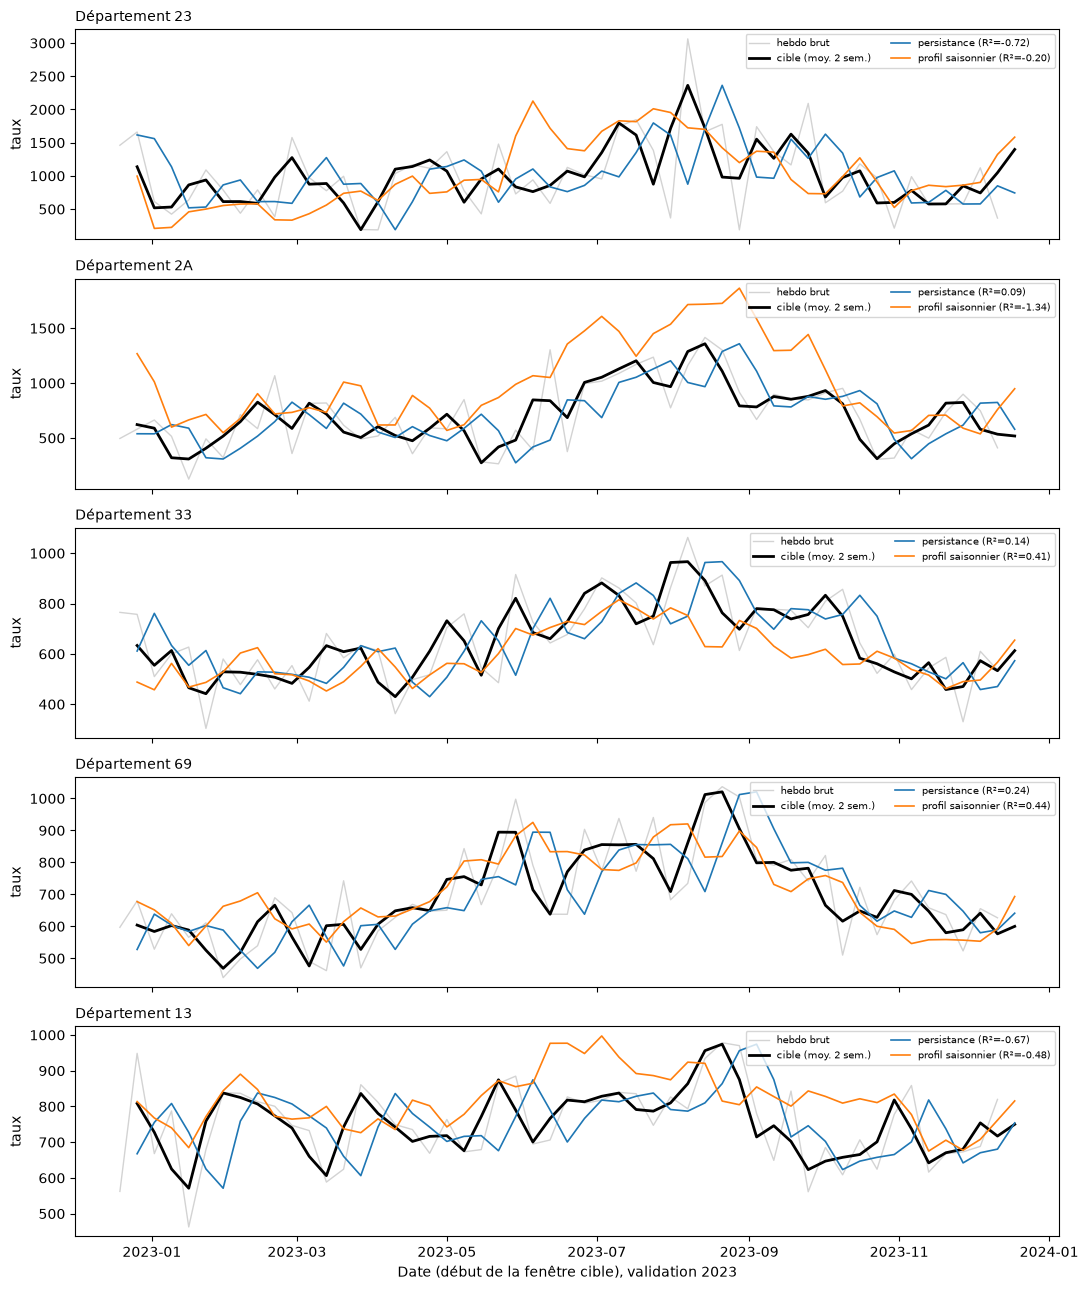

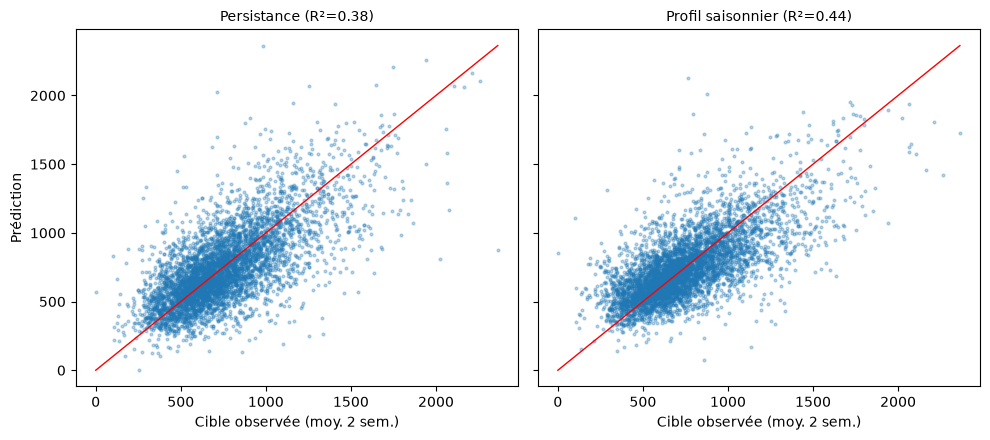

In [2]:
DEPTS = ["23", "2A", "33", "69", "13"] # départements tests

fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = val[val["code_dept"] == dept].sort_values("date_debut")
    sc_p = scores(v["cible"], v["base_persist"])["R2"]
    sc_s = scores(v["cible"], v["base_saison"])["R2"]
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["date_debut"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    ax.plot(v["date_debut"], v["base_persist"], color="tab:blue", lw=1.2,
            label=f"persistance (R²={sc_p:.2f})")
    ax.plot(v["date_debut"], v["base_saison"], color="tab:orange", lw=1.2,
            label=f"profil saisonnier (R²={sc_s:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (début de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharex=True, sharey=True)
for ax, col, nom in zip(axes, ["base_persist", "base_saison"], ["Persistance", "Profil saisonnier"]):
    ax.scatter(val["cible"], val[col], s=4, alpha=0.3)
    lim = [0, val[["cible", col]].max().max()]
    ax.plot(lim, lim, color="red", lw=1)       
    ax.set_title(f"{nom} (R²={scores(val['cible'], val[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

FEATURES = ["y_lag0", "y_moy2", "sem_sin", "sem_cos"] #+ EXOS
CAT = []
NUM = [c for c in FEATURES if c not in CAT]

prep = ColumnTransformer([
    ("num", StandardScaler(), NUM),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), CAT),
])
modele = Pipeline([("prep", prep), ("reg", LinearRegression())])

train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible"])

modele.fit(train[FEATURES], train["cible"])
print("LR val :", scores(val_m["cible"], modele.predict(val_m[FEATURES])))

LR val : {'R2': 0.5099779357527179, 'MAE': 148.48415560333305, 'RMSE': 199.16231675199788}


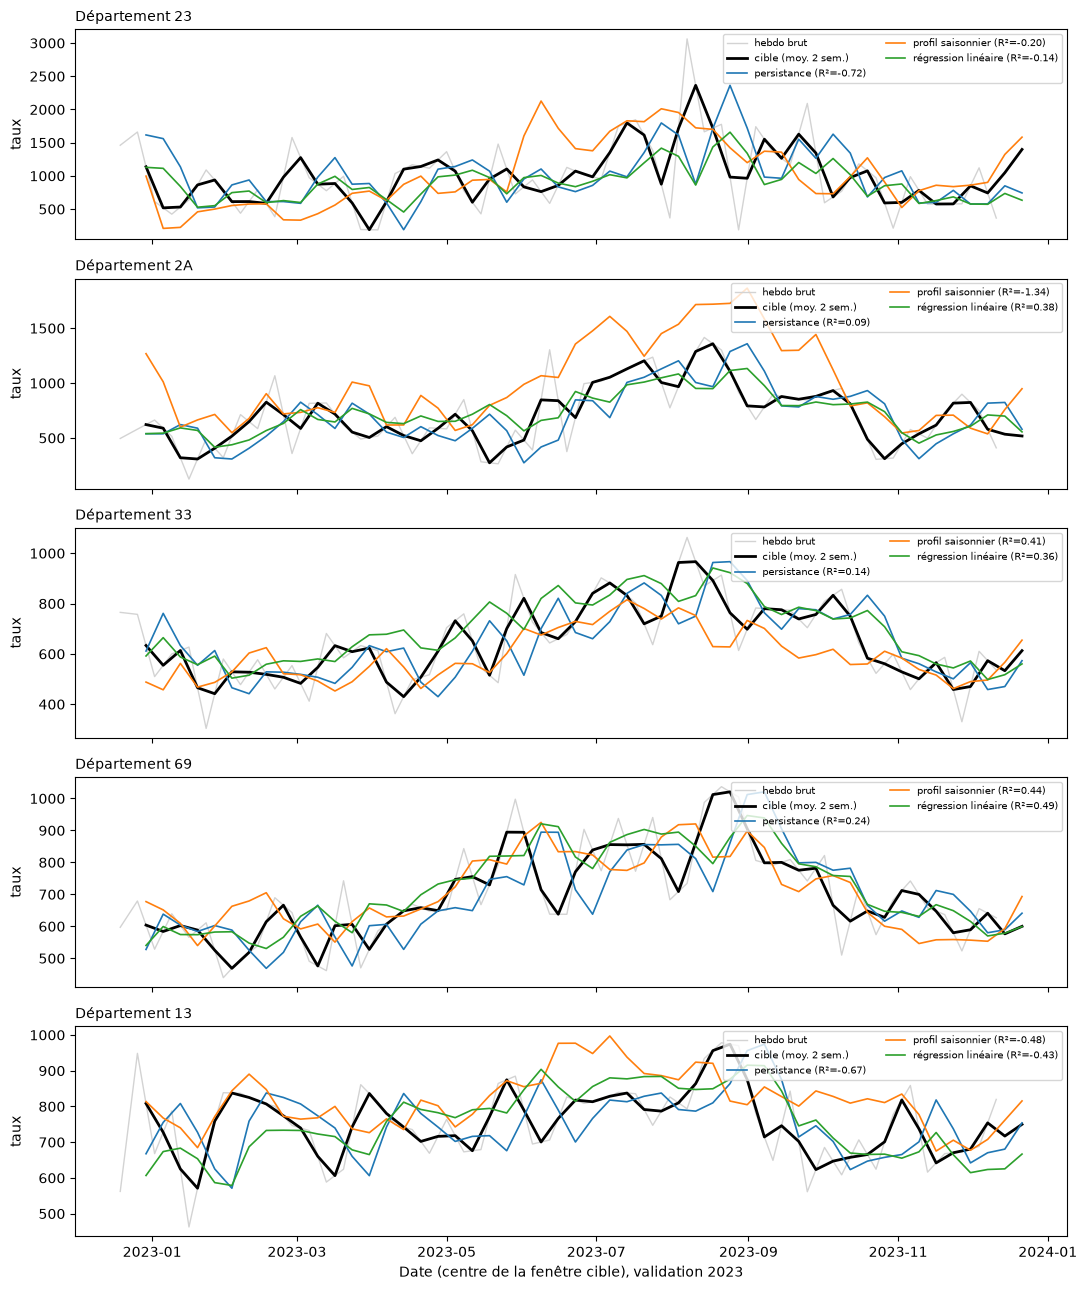

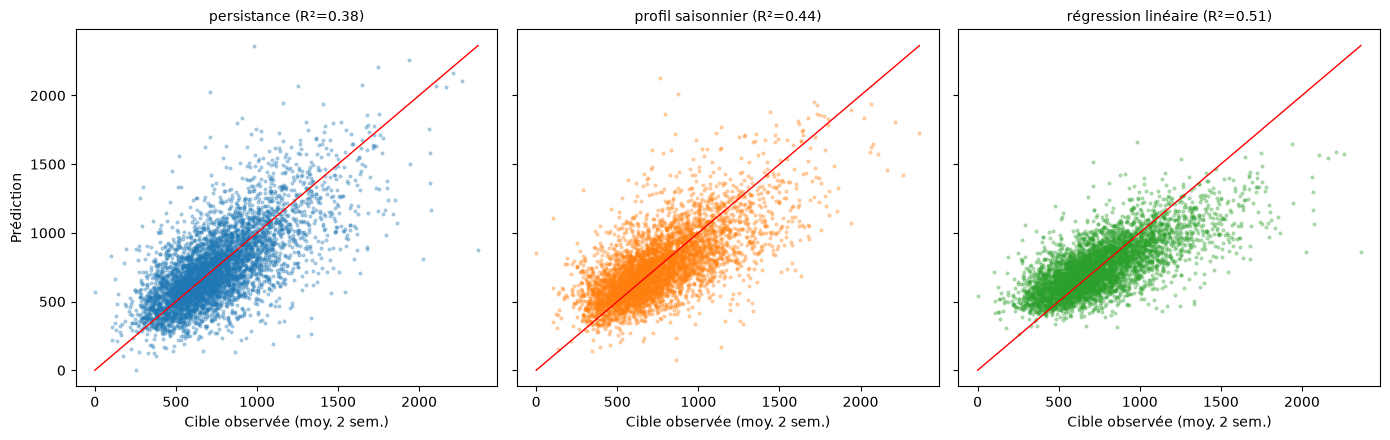

In [4]:
# Prédictions du modèle sur VAL
v_all = val_m.dropna(subset=["base_saison"]).copy()
v_all["pred_LR"] = modele.predict(v_all[FEATURES])
v_all["centre"] = v_all["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("base_persist", "persistance", "tab:blue"),
          ("base_saison",  "profil saisonnier", "tab:orange"),
          ("pred_LR",      "régression linéaire", "tab:green")]

# Hebdo brut
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    v = v_all[v_all["code_dept"] == dept].sort_values("date_debut")
    ax.plot(v["date_debut"] - pd.Timedelta(weeks=1), v["y_lag0"],
            color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(v["centre"], v["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom, coul in SERIES:
        r2 = scores(v["cible"], v[col])["R2"]
        ax.plot(v["centre"], v[col], color=coul, lw=1.2, label=f"{nom} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# Prédictions
fig, axes = plt.subplots(1, len(SERIES), figsize=(14, 4.5), sharex=True, sharey=True)
lim = [0, v_all[["cible"] + [c for c, _, _ in SERIES]].max().max()]
for ax, (col, nom, coul) in zip(axes, SERIES):
    ax.scatter(v_all["cible"], v_all[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="red", lw=1)   
    ax.set_title(f"{nom} (R²={scores(v_all['cible'], v_all[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

k = 2 : silhouette = 0.468
k = 3 : silhouette = 0.439
k = 4 : silhouette = 0.396
k = 5 : silhouette = 0.375
k = 6 : silhouette = 0.377
k retenu : 2


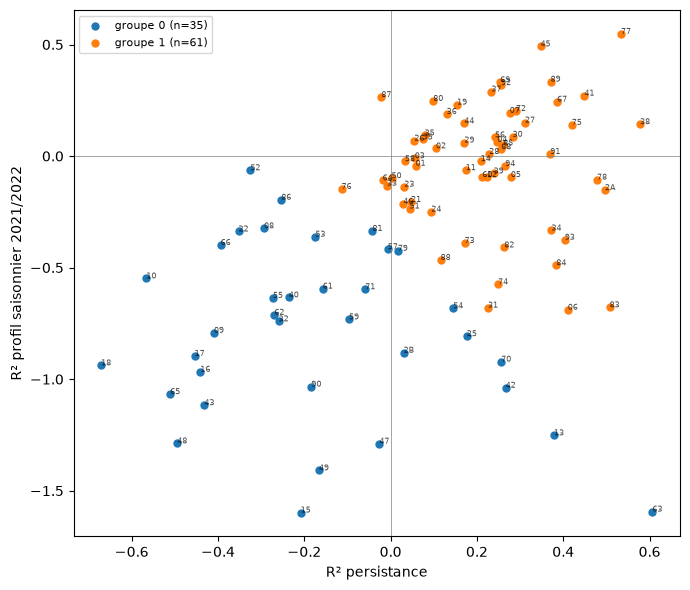

       LR globale  LR par groupe  n_dept
0           0.398          0.399    35.0
1           0.562          0.569    61.0
TOTAL       0.510          0.515    96.0


In [5]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.base import clone

def r2_par_dept(d, cols):
    return (d.groupby("code_dept")
             .apply(lambda g: pd.Series({nom: r2_score(g["cible"], g[c]) for nom, c in cols.items()}))
             .dropna())
    
# Profil saisonnier 
tr0 = panel[panel["split"] == "train"].copy()
tr0["an"] = tr0["date_debut"].dt.isocalendar().year.astype(int)      
cle = ["code_dept", "sem_debut", "an"]
# 2021 sert de saisonnalité à 2022, et vice-versa
autre = tr0[cle + ["cible"]].copy()
autre["an"] = autre["an"].map({2021: 2022, 2022: 2021})
autre = autre.rename(columns={"cible": "saison_autre"})
tr0 = tr0.merge(autre, on=cle, how="left").dropna(subset=["cible", "base_persist", "saison_autre"])
ind = r2_par_dept(tr0, {"r2_persist": "base_persist", "r2_saison": "saison_autre"})

# KMeans 
X = StandardScaler().fit_transform(ind)
sil = {}
for k in range(2, 7):
    groupes = KMeans(k, n_init=20, random_state=0).fit_predict(X)
    sil[k] = silhouette_score(X, groupes)
    print(f"k = {k} : silhouette = {sil[k]:.3f}")
k_opt = pd.Series(sil).idxmax()
print("k retenu :", k_opt)
ind["cluster"] = KMeans(k_opt, n_init=20, random_state=0).fit_predict(X)

fig, ax = plt.subplots(figsize=(7, 6))
for k, g in ind.groupby("cluster"):
    ax.scatter(g["r2_persist"], g["r2_saison"], s=25, label=f"groupe {k} (n={len(g)})")
    for dept, r in g.iterrows():
        ax.annotate(dept, (r["r2_persist"], r["r2_saison"]), fontsize=6, alpha=0.7)
ax.axhline(0, color="grey", lw=0.5)
ax.axvline(0, color="grey", lw=0.5)
ax.set_xlabel("R² persistance")
ax.set_ylabel("R² profil saisonnier 2021/2022")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# LR globale vs LR par groupe
panel["cluster"] = panel["code_dept"].map(ind["cluster"])
train = panel[panel["split"] == "train"].dropna(subset=FEATURES + ["cible", "cluster"])
val_m = panel[panel["split"] == "val"].dropna(subset=FEATURES + ["cible", "cluster"]).copy()

val_m["pred_global"] = clone(modele).fit(train[FEATURES], train["cible"]).predict(val_m[FEATURES])
val_m["pred_groupe"] = np.nan
for k, tr_k in train.groupby("cluster"):
    sel = val_m["cluster"] == k
    val_m.loc[sel, "pred_groupe"] = clone(modele).fit(tr_k[FEATURES], tr_k["cible"]).predict(val_m.loc[sel, FEATURES])

lr = {"LR globale": "pred_global", "LR par groupe": "pred_groupe"}
groupes = {k: g for k, g in val_m.groupby("cluster")}
groupes["TOTAL"] = val_m

lignes = {}
for k, g in groupes.items():
    lignes[k] = {nom: r2_score(g["cible"], g[c]) for nom, c in lr.items()}
    lignes[k]["n_dept"] = g["code_dept"].nunique()
print(pd.DataFrame(lignes).T.round(3))

Sur la carte, sans valeur : []


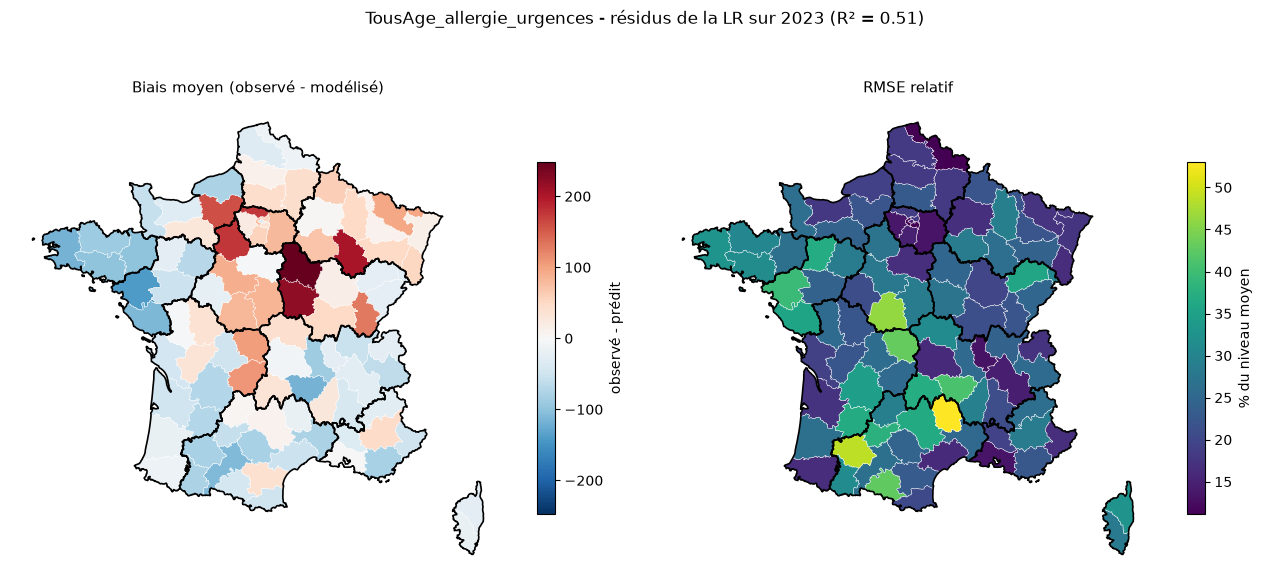

In [6]:
import geopandas as gpd

# Résidus de LR globale 
val_m["predit"] = val_m["pred_global"]
val_m["residu"] = val_m["cible"] - val_m["predit"]

# Métriques par département
par_dept = val_m.groupby("code_dept").apply(lambda g: pd.Series({
    "biais": g["residu"].mean(),           
    "rmse_rel": 100 * np.sqrt((g["residu"] ** 2).mean()) / g["cible"].mean()}))
par_dept.index = par_dept.index.astype(str).str.zfill(2)                       

BASE = "https://raw.githubusercontent.com/gregoiredavid/france-geojson/master/"
carte = gpd.read_file(BASE + "departements-version-simplifiee.geojson")[["code", "nom", "geometry"]]
regions = gpd.read_file(BASE + "regions-version-simplifiee.geojson")
carte = carte.merge(par_dept, left_on="code", right_index=True, how="left")
print("Sur la carte, sans valeur :", carte.loc[carte["biais"].isna(), "code"].tolist())

lim_b = carte["biais"].abs().max()
panneaux = [("biais",    "Biais moyen (observé - modélisé)", "RdBu_r",  -lim_b, lim_b, "observé - prédit"),
            ("rmse_rel", "RMSE relatif", "viridis", None,   None,  "% du niveau moyen")]

fig, axes = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, (col, titre, cmap, lo, hi, lab) in zip(axes, panneaux):
    carte.plot(column=col, cmap=cmap, vmin=lo, vmax=hi, ax=ax, edgecolor="white", linewidth=0.3,
               legend=True, legend_kwds={"shrink": 0.6, "label": lab},
               missing_kwds={"color": "lightgrey"})
    regions.boundary.plot(ax=ax, color="black", linewidth=1.2)
    ax.set_title(titre, fontsize=11)
    ax.set_axis_off()
fig.suptitle(f"{CIBLE} - résidus de la LR sur 2023 "
             f"(R² = {r2_score(val_m['cible'], val_m['predit']):.2f})", fontsize=12)
plt.tight_layout()
plt.show()

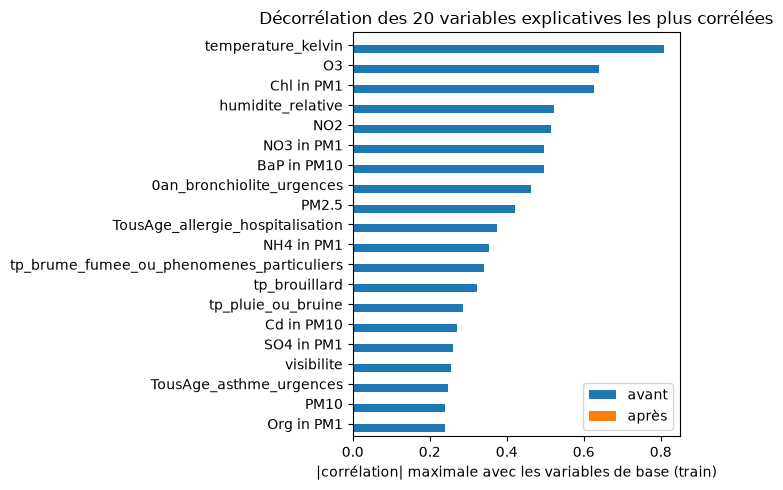

In [7]:
from fairlearn.preprocessing import CorrelationRemover

BASE_F = ["y_lag0", "y_moy2", "sem_sin", "sem_cos"]
cols = BASE_F + EXOS
tr = panel[panel["split"] == "train"].dropna(subset=cols + ["cible"])
va = panel[panel["split"] == "val"].dropna(subset=cols + ["cible"])

# Décorrélation des EXOS
cr = CorrelationRemover(sensitive_feature_ids=BASE_F).fit(tr[cols])
X_tr = pd.DataFrame(cr.transform(tr[cols]), columns=EXOS, index=tr.index)
X_va = pd.DataFrame(cr.transform(va[cols]), columns=EXOS, index=va.index)

def corr_max(X):
    tout = pd.concat([tr[BASE_F], X], axis=1)
    corr = tout.corr().loc[EXOS, BASE_F]
    return corr.abs().max(axis=1)

comp = (pd.DataFrame({"avant": corr_max(tr[EXOS]), "après": corr_max(X_tr)})
          .nlargest(20, "avant").sort_values("avant"))
fig, ax = plt.subplots(figsize=(7, 5))
comp.plot.barh(ax=ax, width=0.8)
ax.set_xlabel("|corrélation| maximale avec les variables de base (train)")
ax.set_title("Décorrélation des 20 variables explicatives les plus corrélées")
plt.tight_layout()
plt.show()

In [8]:
r_tr = tr["cible"] - modele.predict(tr[FEATURES])
r_va = va["cible"] - modele.predict(va[FEATURES])

# Modélisation des résidus de la cible par EXOS décorrélés (cellule préczédente)
mod_res = Pipeline([("sc", StandardScaler()), ("reg", LinearRegression())]).fit(X_tr, r_tr)
corr_va = mod_res.predict(X_va)
print("R² des résidus expliqué (val) :", round(r2_score(r_va, corr_va), 3))
print("Cible, base seule :", scores(va["cible"], va["cible"] - r_va))
print("Cible, base + EXOS :", scores(va["cible"], va["cible"] - r_va + corr_va))

va = va.assign(residu=r_va, residu2=r_va - corr_va) 

# Calcul d'importance par occlusion de bloc
BLOCS = {
    "socio-démo": [c for c in EXOS if c.startswith("pct_")],
    "offre de soins": [c for c in EXOS if c.startswith("densite_")],
    "prévalence": [c for c in EXOS if c.startswith("prev_calc")],
    "autres recours": [c for c in EXOS if c.startswith(("TousAge_", "0an_", "sos_"))],
    "pollution": [c for c in EXOS if c in ("PM10", "PM2.5", "O3", "NO2", "SO2") or " in PM" in c],
}
deja = [c for v in BLOCS.values() for c in v]
BLOCS["météo"] = [c for c in EXOS if c not in deja]

def r2_sans(exclus):
    garde = [c for c in EXOS if c not in exclus]
    m = Pipeline([("sc", StandardScaler()), ("reg", LinearRegression())]).fit(X_tr[garde], r_tr)
    return r2_score(r_va, m.predict(X_va[garde]))

r2_tout = r2_score(r_va, corr_va)
print(pd.Series({b: r2_tout - r2_sans(v) for b, v in BLOCS.items()})
      .sort_values(ascending=False).round(3).rename("perte de R² par occlusion"))

R² des résidus expliqué (val) : 0.073
Cible, base seule : {'R2': 0.5149617246844888, 'MAE': 147.3993105322376, 'RMSE': 197.47378593769258}
Cible, base + EXOS : {'R2': 0.5501888225872396, 'MAE': 141.0310984068741, 'RMSE': 190.16761882335175}
socio-démo        0.018
offre de soins    0.007
autres recours    0.005
météo             0.005
prévalence        0.003
pollution         0.000
Name: perte de R² par occlusion, dtype: float64


In [9]:
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

# Concordance départements # régions
REGIONS = {
    "ARA": ["01","03","07","15","26","38","42","43","63","69","73","74"],
    "BFC": ["21","25","39","58","70","71","89","90"],
    "BRE": ["22","29","35","56"],
    "CVL": ["18","28","36","37","41","45"],
    "COR": ["2A","2B"],
    "GES": ["08","10","51","52","54","55","57","67","68","88"],
    "HDF": ["02","59","60","62","80"],
    "IDF": ["75","77","78","91","92","93","94","95"],
    "NOR": ["14","27","50","61","76"],
    "NAQ": ["16","17","19","23","24","33","40","47","64","79","86","87"],
    "OCC": ["09","11","12","30","31","32","34","46","48","65","66","81","82"],
    "PDL": ["44","49","53","72","85"],
    "PAC": ["04","05","06","13","83","84"],
}
dept_region = {}
for region, depts in REGIONS.items():
    for dept in depts:
        dept_region[dept] = region

# Résidus VAL 2023
val_m["predit"] = val_m["pred_global"]
val_m["residu"] = val_m["cible"] - val_m["predit"]
print(f"Validation : {val_m['residu'].notna().sum()} résidus, {val_m['code_dept'].nunique()} départements")

# Biais moyen par département (après LR base) et région de rattachement
b = val_m.groupby("code_dept")["residu"].mean().rename("biais").to_frame()
b.index = b.index.astype(str).str.zfill(2)
b["region"] = b.index.map(dept_region)
print("Départements sans région :", b.index[b["region"].isna()].tolist())

# ANOVA par région
anova = smf.ols("biais ~ C(region)", data=b.dropna()).fit()
print(anova_lm(anova).round(3))
print(f"Variance des biais expliquée par régions : R² = {anova.rsquared:.2f} ")
print(b.groupby("region")["biais"].agg(["mean", "count"]).sort_values("mean").round(1))

Validation : 4992 résidus, 96 départements
Départements sans région : []
             df      sum_sq    mean_sq      F  PR(>F)
C(region)  12.0  250799.815  20899.985  5.376     0.0
Residual   83.0  322703.279   3887.991    NaN     NaN
Variance des biais expliquée par régions : R² = 0.44 
         mean  count
region              
BRE    -101.6      4
PDL     -80.1      5
OCC     -45.8     13
ARA     -29.4     12
PAC     -24.4      6
COR     -22.4      2
NAQ      -3.4     12
NOR       4.8      5
HDF      11.5      5
IDF      58.1      8
GES      61.1     10
CVL      67.4      6
BFC      73.2      8


In [10]:
# Résidus TRAIN 2021-2022 (LR base)
d = tr.reset_index(drop=True)
d["residu"] = d["cible"] - modele.predict(d[FEATURES])
d["code_dept"] = d["code_dept"].astype(str).str.zfill(2)
d["region"] = d["code_dept"].map(dept_region)
print(f"Train : {len(d)} lignes, résidu moyen = {d['residu'].mean():.2f}, écart-type = {d['residu'].std():.1f}")

# EXOS standardisées sur le train, renommées x0, x1... pour la formule
sc = StandardScaler().fit(d[EXOS])
noms_x = [f"x{i}" for i in range(len(EXOS))]
d = pd.concat([d, pd.DataFrame(sc.transform(d[EXOS]), columns=noms_x)], axis=1)

# Modèles mixtes sur les résidus : intercepts aléatoires région et département dans la région
def modele_mixte(formule):
    mm = smf.mixedlm(formule, d, groups="region", re_formula="1", vc_formula={"dept": "0 + C(code_dept)"})
    return mm.fit(reml=False, method="bfgs")

m0 = modele_mixte("residu ~ 1")
m1 = modele_mixte("residu ~ " + " + ".join(noms_x))

# Variances région, département et semaine, sans puis avec EXOS
comp = pd.DataFrame({
    "résidus seuls": [m0.cov_re.iloc[0, 0], m0.vcomp[0], m0.scale],
    "résidus + EXOS": [m1.cov_re.iloc[0, 0], m1.vcomp[0], m1.scale],
}, index=["région", "département", "semaine"])
pourcent = 100 * comp / comp.sum()
pourcent.index = ["région (%)", "département (%)", "semaine (%)"]
print(pourcent.round(1))
expl = 1 - comp["résidus + EXOS"] / comp["résidus seuls"]
print(f"Variance départementale expliquée par les EXOS : {expl['département']:.0%}")
print(f"Variance régionale expliquée par les EXOS : {expl['région']:.0%}")

# Écarts région + département estimés par un modèle mixte
def ecarts(m, region, dept):
    e = m.random_effects[region]
    # e.iloc[0] : écart de la région ; puis écart du département dans sa région
    return e.iloc[0] + e[f"dept[C(code_dept)[{dept}]]"]

# VAL 2023 : lignes où toutes les EXOS sont disponibles, communes aux trois prédictions
w = val_m.dropna(subset=["cible", "pred_global"] + EXOS).reset_index(drop=True)
w["code_dept"] = w["code_dept"].astype(str).str.zfill(2)
w["region"] = w["code_dept"].map(dept_region)
X = pd.DataFrame(sc.transform(w[EXOS]), columns=noms_x)

ec0 = [ecarts(m0, r, c) for r, c in zip(w["region"], w["code_dept"])]
ec1 = [ecarts(m1, r, c) for r, c in zip(w["region"], w["code_dept"])]
w["pred_mm"] = w["pred_global"] + m0.fe_params["Intercept"] + ec0
w["pred_mm_exos"] = w["pred_global"] + m1.fe_params["Intercept"] + X @ m1.fe_params[noms_x] + ec1

print(f"\nValidation : {len(w)} lignes, {w['code_dept'].nunique()} départements")
print("LR base :", scores(w["cible"], w["pred_global"]))
print("LR base + MM :", scores(w["cible"], w["pred_mm"]))
print("LR base + MM EXOS :", scores(w["cible"], w["pred_mm_exos"]))

Train : 9639 lignes, résidu moyen = 0.28, écart-type = 206.0
                 résidus seuls  résidus + EXOS
région (%)                 4.2             2.4
département (%)            5.5             2.6
semaine (%)               90.4            95.0
Variance départementale expliquée par les EXOS : 55%
Variance régionale expliquée par les EXOS : 47%

Validation : 4949 lignes, 96 départements
LR base : {'R2': 0.5149617246844888, 'MAE': 147.3993105322376, 'RMSE': 197.47378593769258}
LR base + MM : {'R2': 0.5722798713750648, 'MAE': 136.81566590139215, 'RMSE': 185.43909168305547}
LR base + MM EXOS : {'R2': 0.5749464628495278, 'MAE': 136.12620377231647, 'RMSE': 184.86013432749652}


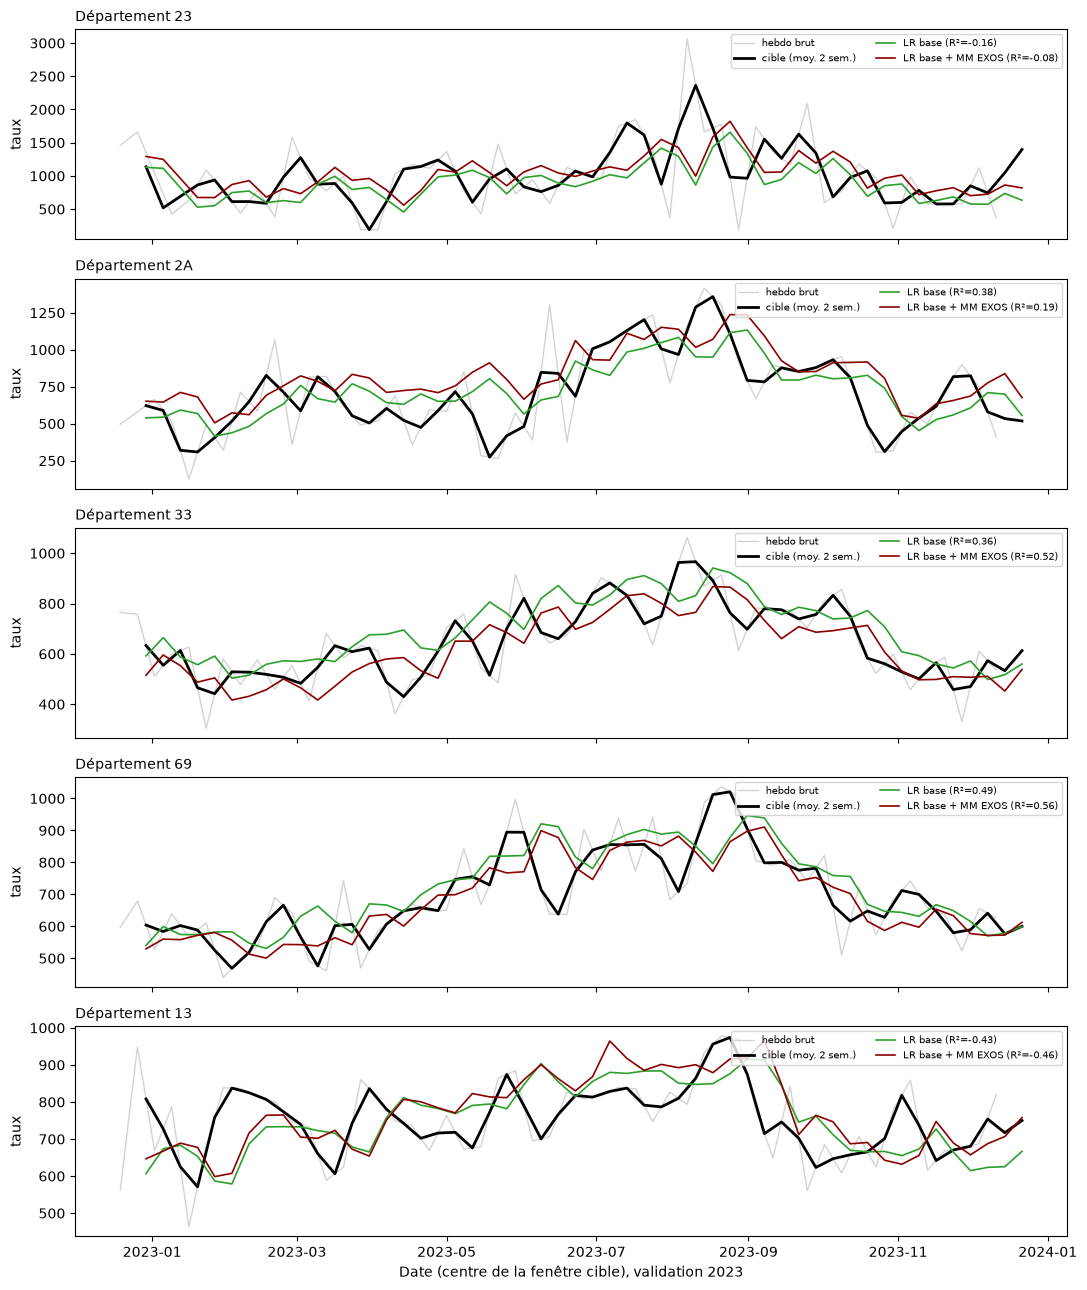

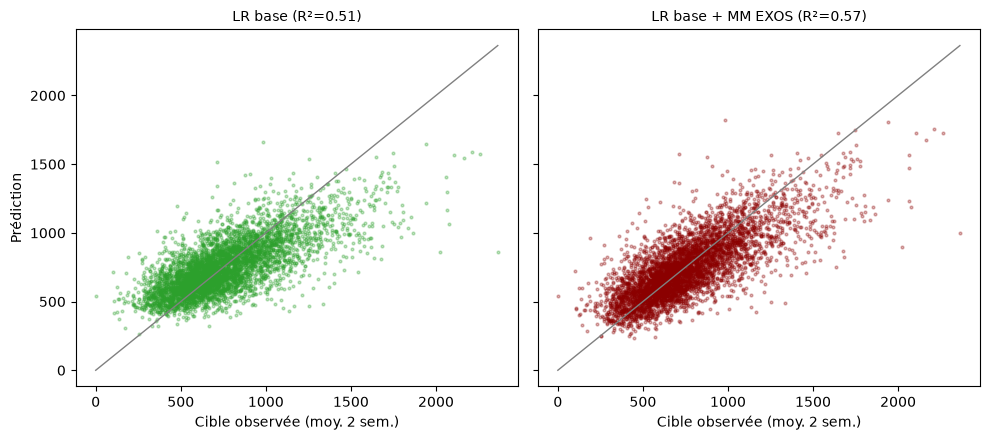

In [11]:
# Prédictions VAL 2023 (lignes avec EXOS, cellule précédente)
w["centre"] = w["date_debut"] + pd.Timedelta(weeks=(H - 1) / 2)

SERIES = [("pred_global", "LR base", "tab:green"),
          ("pred_mm_exos", "LR base + MM EXOS", "darkred")]

# Séries temporelles
fig, axes = plt.subplots(len(DEPTS), 1, figsize=(11, 2.6 * len(DEPTS)), sharex=True)
for ax, dept in zip(axes, DEPTS):
    vd = w[w["code_dept"] == dept].sort_values("date_debut")
    ax.plot(vd["date_debut"] - pd.Timedelta(weeks=1), vd["y_lag0"], color="lightgrey", lw=1, label="hebdo brut")
    ax.plot(vd["centre"], vd["cible"], color="black", lw=2, label=f"cible (moy. {H} sem.)")
    for col, nom_s, coul in SERIES:
        r2 = scores(vd["cible"], vd[col])["R2"]
        ax.plot(vd["centre"], vd[col], color=coul, lw=1.2, label=f"{nom_s} (R²={r2:.2f})")
    ax.set_title(f"Département {dept}", fontsize=10, loc="left")
    ax.set_ylabel("taux")
    ax.legend(fontsize=7, loc="upper right", ncol=2)
axes[-1].set_xlabel("Date (centre de la fenêtre cible), validation 2023")
plt.tight_layout()
plt.show()

# Prédit vs observé
fig, axes = plt.subplots(1, len(SERIES), figsize=(10, 4.5), sharex=True, sharey=True)
lim = [0, w[["cible"] + [c for c, _, _ in SERIES]].max().max()]
for ax, (col, nom_s, coul) in zip(axes, SERIES):
    ax.scatter(w["cible"], w[col], s=4, alpha=0.3, color=coul)
    ax.plot(lim, lim, color="grey", lw=1)
    ax.set_title(f"{nom_s} (R²={scores(w['cible'], w[col])['R2']:.2f})", fontsize=10)
    ax.set_xlabel(f"Cible observée (moy. {H} sem.)")
axes[0].set_ylabel("Prédiction")
plt.tight_layout()
plt.show()

In [12]:
# LR base + MM : métriques sur TRAIN, VAL et TEST
lignes = []
for nom_split in ["train", "val", "test"]:
    s = panel[panel["split"] == nom_split].dropna(subset=FEATURES + ["cible"]).reset_index(drop=True)
    s["code_dept"] = s["code_dept"].astype(str).str.zfill(2)
    s["region"] = s["code_dept"].map(dept_region)

    pred_lr = modele.predict(s[FEATURES])
    corr = [ecarts(m0, r, c) for r, c in zip(s["region"], s["code_dept"])]
    pred_mm = pred_lr + m0.fe_params["Intercept"] + np.array(corr)

    for nom_modele, pred in [("LR base", pred_lr), ("LR base + MM", pred_mm)]:
        ligne = scores(s["cible"], pred)
        ligne["split"] = nom_split
        ligne["modèle"] = nom_modele
        ligne["n"] = len(s)
        lignes.append(ligne)

print(pd.DataFrame(lignes).set_index(["split", "modèle"]).round(4))

                        R2       MAE      RMSE     n
split modèle                                        
train LR base       0.4672  150.9219  206.7204  9696
      LR base + MM  0.5181  141.6694  196.5950  9696
val   LR base       0.5100  148.4842  199.1623  4992
      LR base + MM  0.5661  138.0279  187.4113  4992
test  LR base       0.4368  143.7327  192.1032  4992
      LR base + MM  0.4998  133.4261  181.0466  4992
